In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import time
import cv2
import numpy as np
import sys
sys.path.append('/content/drive/MyDrive/simuteh-2330511092/src')
from utils_cv import kontras_bercak, baca

def konvolusi(img, k): # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k): # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"drive/MyDrive/simuteh-2330511092/data/sintetis/bersih/{nama}"),
 cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama}", 0)
for nm, k in {"rerata": np.ones((3, 3)) / 9,
 "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
 }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.381 s, filter2D=0.00056 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.922 s, filter2D=0.00051 s


In [5]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):
    # p = proporsi piksel rusak
    out = img.copy()
    m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):
    # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {
    "gauss_10": derau_gauss(bersih, 10),
    "gauss_20": derau_gauss(bersih, 20),
    "gauss_40": derau_gauss(bersih, 40),
    "sp_4%": derau_sp(bersih, 0.04),
    "sp_10%": derau_sp(bersih, 0.10)
}

penapis = {
    "rerata_3": lambda x: cv2.blur(x, (3, 3)),
    "rerata_5": lambda x: cv2.blur(x, (5, 5)),
    "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "median_3": lambda x: cv2.medianBlur(x, 3),
    "median_5": lambda x: cv2.medianBlur(x, 5),
    "median_9": lambda x: cv2.medianBlur(x, 9)
}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d), kontras_bercak(out, md, mb)])

tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)

# Menampilkan hasil khusus untuk disalin ke Tabel 11 (gauss_20 dan sp_4%)
print("--- Data untuk Tabel 11 (Derau Gaussian 20) ---")
print(tabel[tabel['derau'] == 'gauss_20'])
print("\n--- Data untuk Tabel 11 (Derau Garam-Merica 4%) ---")
print(tabel[tabel['derau'] == 'sp_4%'])

# Menyimpan seluruh hasil
# Sesuaikan path penyimpanan agar tidak error
tabel.to_csv("/content/drive/MyDrive/simuteh-2330511092/data/sintetis/b4_tabel_penapisan.csv", index=False)

--- Data untuk Tabel 11 (Derau Gaussian 20) ---
       derau   penapis  PSNR_dB  waktu_ms    KB
7   gauss_20     tanpa    22.11      0.00  1.92
8   gauss_20  rerata_3    31.41      0.13  4.33
9   gauss_20  rerata_5    34.40      0.17  5.15
10  gauss_20   gauss_5    32.55      0.30  4.64
11  gauss_20  median_3    29.72      0.11  3.90
12  gauss_20  median_5    33.40      0.91  5.05
13  gauss_20  median_9    35.23     17.23  5.80

--- Data untuk Tabel 11 (Derau Garam-Merica 4%) ---
    derau   penapis  PSNR_dB  waktu_ms    KB
21  sp_4%     tanpa    19.18      0.00  1.44
22  sp_4%  rerata_3    28.33      0.13  3.59
23  sp_4%  rerata_5    31.60      0.17  4.71
24  sp_4%   gauss_5    29.46      0.30  3.99
25  sp_4%  median_3    47.62      0.11  6.38
26  sp_4%  median_5    44.28      0.91  6.60
27  sp_4%  median_9    40.07     20.27  7.45


[Peringatan] File dilewati karena tidak ditemukan: teh_036.png

--- Rerata dI dan KB berdasarkan Ukuran Kernel (Kelas Ringan) ---
           dI    KB
kernel             
1       23.57  3.70
3       23.99  3.83
5       22.87  3.70
9       16.80  3.16
15       6.74  1.84


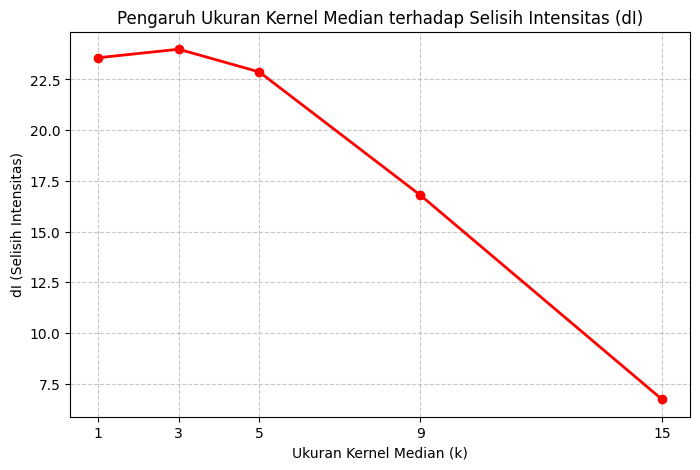

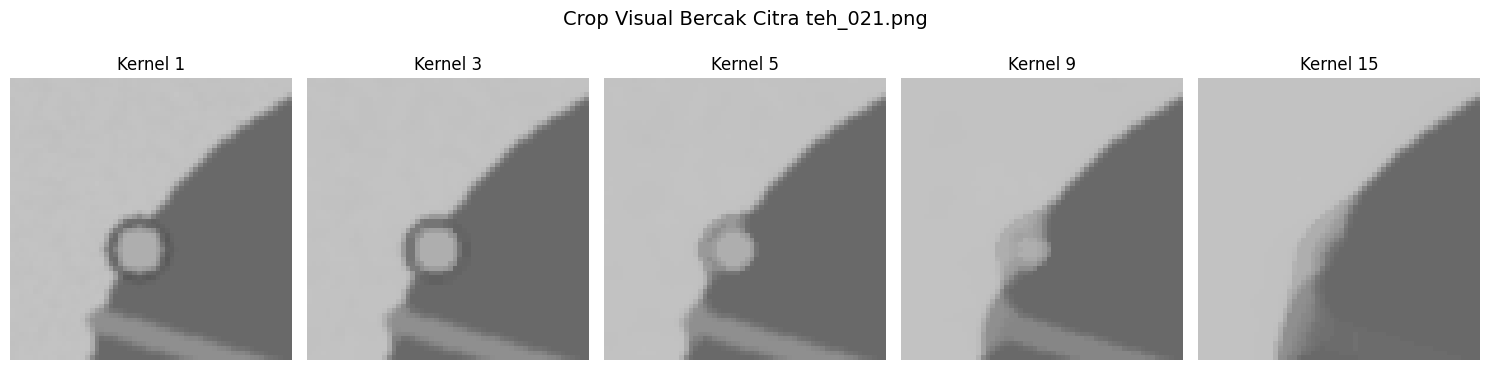

In [11]:
import os
import matplotlib.pyplot as plt

# --- 1. Fungsi Selisih Rerata dan Perhitungan ---
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

path_base = "/content/drive/MyDrive/simuteh-2330511092/data/sintetis"
label = pd.read_csv(f"{path_base}/label.csv")
baris = []

# Mengambil 20 citra kelas ringan
for nm in label[label['kelas'] == "ringan"]['nama_file']:
    try:
        g = cv2.cvtColor(baca(f"{path_base}/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
        md2 = cv2.imread(f"{path_base}/mask_daun/{nm}", 0)
        mb2 = cv2.imread(f"{path_base}/mask_bercak/{nm}", 0)
        if md2 is None or mb2 is None:
            continue
    except FileNotFoundError:
        print(f"[Peringatan] File dilewati karena tidak ditemukan: {nm}")
        continue

    for k in [1, 3, 5, 9, 15]:  # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
tabel_rerata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)

print("\n--- Rerata dI dan KB berdasarkan Ukuran Kernel (Kelas Ringan) ---")
print(tabel_rerata)


# --- 2. Membuat Grafik dI terhadap Ukuran Kernel ---
plt.figure(figsize=(8, 5))
plt.plot(tabel_rerata.index, tabel_rerata["dI"], marker='o', linestyle='-', color='red', linewidth=2)
plt.title("Pengaruh Ukuran Kernel Median terhadap Selisih Intensitas (dI)")
plt.xlabel("Ukuran Kernel Median (k)")
plt.ylabel("dI (Selisih Intensitas)")
plt.xticks([1, 3, 5, 9, 15])
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


# --- 3. Perbesar (Crop) Satu Bercak Secara Visual ---
# Mengambil sampel 1 citra ringan (teh_021.png)
nm_sampel = "teh_021.png"
try:
    g_sampel = cv2.cvtColor(baca(f"{path_base}/bersih/{nm_sampel}"), cv2.COLOR_BGR2GRAY)
    mb_sampel = cv2.imread(f"{path_base}/mask_bercak/{nm_sampel}", 0)

    # Mencari koordinat piksel bercak pertama secara otomatis
    y_bercak, x_bercak = np.where(mb_sampel > 0)
    if len(y_bercak) > 0:
        cy, cx = y_bercak[0], x_bercak[0]  # Titik pusat potongan
        r = 30  # Radius potongan (crop 60x60 piksel)

        plt.figure(figsize=(15, 4))
        kernels = [1, 3, 5, 9, 15]
        for i, k in enumerate(kernels):
            out = g_sampel if k == 1 else cv2.medianBlur(g_sampel, k)

            # Batasi area crop agar tidak error jika di ujung gambar
            y1, y2 = max(0, cy-r), min(out.shape[0], cy+r)
            x1, x2 = max(0, cx-r), min(out.shape[1], cx+r)
            crop_img = out[y1:y2, x1:x2]

            plt.subplot(1, len(kernels), i+1)
            plt.imshow(crop_img, cmap='gray', vmin=0, vmax=255)
            plt.title(f"Kernel {k}")
            plt.axis('off')

        plt.suptitle(f"Crop Visual Bercak Citra {nm_sampel}", fontsize=14)
        plt.tight_layout()
        plt.show()
except FileNotFoundError:
    print(f"Citra sampel {nm_sampel} tidak ditemukan untuk visualisasi crop.")

In [12]:
def unsharp(x, k=1.0):
 blur = cv2.GaussianBlur(x, (5, 5), 1.0)
 return cv2.addWeighted(x, 1 + k, blur, -k, 0)
noisy = derau["gauss_20"]
latar = md == 0 # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
 "Median": lambda x: cv2.medianBlur(x, 5)}.items():
 A = redam(unsharp(noisy)) # tajamkan dulu, lalu redam
 B = unsharp(redam(noisy)) # redam dulu, lalu tajamkan
 print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
 f"sigma_latar={A[latar].std():.1f} | redam->tajam "
 f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.37 sigma_latar=7.8 | redam->tajam PSNR=30.19 sigma_latar=8.1
Median: tajam->redam PSNR=30.13 sigma_latar=8.0 | redam->tajam PSNR=31.10 sigma_latar=7.1


In [14]:
import pandas as pd
import numpy as np
import cv2

path_base = "/content/drive/MyDrive/simuteh-2330511092/data/sintetis"

# 12 citra kondisi normal (loncat tiap 5 nomor)
daftar_uji = [f"teh_{str(i).zfill(3)}.png" for i in range(1, 60, 5)]

# Kita menggunakan penapis Gaussian (5x5) karena baik untuk derau sensor umum
penapis_terbaik = lambda x: cv2.GaussianBlur(x, (5, 5), 1.0)

hasil_psnr = []

print("--- Evaluasi 12 Citra Kondisi Normal (Langkah 4.6) ---")
for nama in daftar_uji:
    # Baca citra asli (dengan derau sensor) dan citra bersih
    raw_asli = cv2.imread(f"{path_base}/citra/{nama}")
    raw_bersih = cv2.imread(f"{path_base}/bersih/{nama}")

    # Validasi apakah gambar berhasil dimuat
    if raw_asli is None or raw_bersih is None:
        print(f"[Peringatan] Berkas {nama} dilewati karena tidak ditemukan di folder asli atau bersih.")
        continue

    img_asli = cv2.cvtColor(raw_asli, cv2.COLOR_BGR2GRAY)
    img_bersih = cv2.cvtColor(raw_bersih, cv2.COLOR_BGR2GRAY)

    # Hitung PSNR sebelum penapisan
    psnr_sebelum = cv2.PSNR(img_bersih, img_asli)

    # Terapkan penapis dan hitung PSNR sesudah penapisan
    img_tapis = penapis_terbaik(img_asli)
    psnr_sesudah = cv2.PSNR(img_bersih, img_tapis)

    hasil_psnr.append({
        "Nama File": nama,
        "PSNR Awal (dB)": round(psnr_sebelum, 2),
        "PSNR Sesudah (dB)": round(psnr_sesudah, 2),
        "Kenaikan": round(psnr_sesudah - psnr_sebelum, 2)
    })

if hasil_psnr:
    df_evaluasi = pd.DataFrame(hasil_psnr)
    print(df_evaluasi.to_string(index=False))
    # Rerata Kenaikan
    print(f"\nRata-rata Kenaikan PSNR: {df_evaluasi['Kenaikan'].mean():.2f} dB")
else:
    print("Tidak ada citra yang berhasil dievaluasi.")

--- Evaluasi 12 Citra Kondisi Normal (Langkah 4.6) ---
[Peringatan] Berkas teh_036.png dilewati karena tidak ditemukan di folder asli atau bersih.
  Nama File  PSNR Awal (dB)  PSNR Sesudah (dB)  Kenaikan
teh_001.png           34.60              42.45      7.85
teh_006.png           32.61              41.01      8.40
teh_011.png           33.42              41.96      8.54
teh_016.png           29.30              38.83      9.53
teh_021.png           28.91              38.60      9.68
teh_026.png           35.12              42.48      7.36
teh_031.png           28.81              38.56      9.75
teh_041.png           29.85              38.86      9.01
teh_046.png           33.75              40.99      7.25
teh_051.png           33.68              40.70      7.02
teh_056.png           32.17              40.16      8.00

Rata-rata Kenaikan PSNR: 8.40 dB


In [15]:
%cd /content/drive/MyDrive/simuteh-2330511092

/content/drive/MyDrive/simuteh-2330511092


In [16]:
!git config --global user.email "gentaaditya18@gmail.com"
!git config --global user.name "Adityagenta"

In [17]:
!git add .

In [18]:
!git commit -m "Bagian 4 done"

[main d9fb8db] Bagian 4 done
 3 files changed, 38 insertions(+), 1 deletion(-)
 create mode 100644 data/sintetis/b4_tabel_penapisan.csv
 create mode 100644 notebook/B4_penapisan.ipynb


In [19]:
!git push origin main

Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (8/8), 65.13 KiB | 4.65 MiB/s, done.
Total 8 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 4 local objects.
To https://github.com/Adityagenta/simuteh-2330511092.git
   ec6b82f..d9fb8db  main -> main
